# DSA211 — Predicting Online Purchases
### Topic 2 · Classification System Evaluation · Voucher revenue revision

**Objective.** Predict whether an online browsing session ends in a purchase (`Revenue = 1`) and assess a model-guided voucher policy under explicit hypothetical assumptions. This is a prediction exercise, not causal inference. The dataset contains historical sessions from one Turkish online retailer over one year.

The statistical decision is `predicted Buy (1) → no voucher`; `predicted No Buy (0) → voucher`. The dataset contains session outcomes without this intervention. Its labels are never changed by the simulation.

**Four assumptions.** (A1) Every voucher is redeemed and converts a session with certainty. (A2) The voucher discounts the order by 20%, with no minimum spend. (A3) Every order has the same representative value `A`, so it cancels from relative revenue. (A4) Recorded labels describe behaviour without the proposed intervention. These are assumptions, not findings. We report simulated sales revenue, not profit; we do not assign a numerical value to `A`.

The analysis compares exactly two business scenarios: the observed no-voucher baseline and the model-guided voucher policy. It does not estimate an actual causal lift.

## 0. Methodology and decision rules

**Objective.** Select the session classifier by mean training-CV ROC-AUC, then optimize only that selected model’s probability threshold for simulated revenue under A1–A4. Report discrimination and policy outcomes separately.

**Methodology.** Keep the established stratified 75/25 train/test split (`random_state=42`) and stratified five-fold CV on training data. Fit every imputer, encoder, transform and scaler within each fold. The historical test partition is evaluated once after choosing a candidate and its threshold from training out-of-fold (OOF) predictions; it has been viewed in the earlier project and is not a fresh independent holdout.

**First-pass requirement.** Attempt Logistic Regression, Gaussian Naive Bayes and LDA with all 17 original predictors. Preserve genuine warnings and failures. After this diagnostic stage, use all 16 predictors other than `PageValues` for operational candidates because `PageValues` may be recorded after the purchase decision. This is a prediction-time availability judgment, not a conclusion from AUC alone.

**Revenue rule.** If `p` is the true no-voucher purchase probability, no-voucher expected revenue is `pA`; voucher revenue under A1–A3 is `0.80A`. Issue a voucher when `p < 0.80`, so the theoretical threshold is **0.80**. This gives opportunity costs `C_FP = 0.80A` (missed discounted sale) and `C_FN = 0.20A` (discount on a purchase that would have happened), hence `C_FN:C_FP = 1:4`. These are not measured losses.

With positive class `Revenue=1`, `R0 = TP + FN` and `Rmodel = TP + 0.80(FN + TN)` in units of `A`. Thus `ΔR = 0.80TN − 0.20FN`, relative change is `ΔR/R0`, and improvement requires `4TN > FN`. The labels remain as observed; only simulated business outcomes differ.

**Revenue equations (in units of `A`).** The cost ratio and threshold follow from the two expected revenues:

$$
\begin{aligned}
C_{FP} &= 0.80A, & C_{FN} &= 0.20A, & C_{FN}:C_{FP} &= 1:4,\\
pA &\geq 0.80A \Longleftrightarrow p \geq 0.80 && \Rightarrow \text{no voucher},\\
t^* &= \frac{C_{FP}}{C_{FP}+C_{FN}} = 0.80.
\end{aligned}
$$

For confusion-matrix counts with `Revenue = 1` as positive:

$$
\begin{aligned}
R_0 &= A(TP+FN),\\
R_{\mathrm{model}} &= A[TP+0.80(FN+TN)],\\
\Delta R &= A(0.80TN-0.20FN),\\
\frac{\Delta R}{R_0} &= \frac{0.80TN-0.20FN}{TP+FN},\\
\Delta R>0 &\Longleftrightarrow 4TN>FN.
\end{aligned}
$$

**Implication.** The theoretical cutoff recommends no voucher for probabilities at or above 0.80 and a voucher below it; threshold comparisons therefore change the assumed policy allocation, not the observed labels.

**Selection.** Rank successful, defensible operational candidates by mean five-fold training AUC; break exact ties deterministically by candidate label. Freeze the highest-AUC model before using revenue. Then, and only for that model, scan exact OOF probability cutpoints including 0, 0.80, 1 and a cutoff above the maximum score. Choose the cutoff with greatest OOF simulated revenue; threshold ties prefer the cutoff nearest 0.80, then the lower cutoff. Since threshold selection and OOF revenue use the same predictions, the reported training policy revenue is optimistic and not an independent unbiased estimate. Average precision is reported as an additional predictive metric but is not a selection criterion.

In [1]:
from pathlib import Path
import json
import hashlib, platform, sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logsumexp
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, FunctionTransformer, PolynomialFeatures)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
    average_precision_score, precision_recall_curve)

SEED, TEST_FRAC, K = 42, .25, 5
C_FP, C_FN = .80, .20  # revenue opportunity costs in units of A
THEORY_THRESHOLD = C_FP / (C_FP + C_FN)
FOLDS = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
NUM_ALL = ['Administrative','Administrative_Duration','Informational','Informational_Duration',
           'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues']
CAT_ALL = ['SpecialDay','Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']
ALL = NUM_ALL + CAT_ALL
PROBLEM_COL = 'PageValues'
NUM_SAFE = [c for c in NUM_ALL if c != PROBLEM_COL]
SAFE = NUM_SAFE + CAT_ALL
pd.set_option('display.max_columns', 24)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)
print(f'Stratified {K}-fold CV; stratified 75/25 split; seed={SEED}')
print(f'Costs in units of A: C_FP={C_FP:.2f}A, C_FN={C_FN:.2f}A; ratio C_FN:C_FP=1:4; theoretical threshold={THEORY_THRESHOLD:.2f}')

Stratified 5-fold CV; stratified 75/25 split; seed=42
Costs in units of A: C_FP=0.80A, C_FN=0.20A; ratio C_FN:C_FP=1:4; theoretical threshold=0.80


## 1. Data quality, split, and training-only EDA

**Objective and method.** Check the source structure, types, missingness and duplicate rows, then retain the historical stratified split. Outcome-related EDA uses training rows only. A duplicate feature row does not establish that two sessions belong to one customer, so rows are not removed.

**Python implementation and results.** The next cell reports the observed data quality and split counts. The test partition stays closed until the selected pipeline and threshold are fixed.

In [2]:
path = Path('data/uci_468.csv')
if not path.is_file():
    raise FileNotFoundError('Run this notebook from repository root; expected data/uci_468.csv')
raw = pd.read_csv(path)
expected = set(ALL + ['Revenue'])
if set(raw.columns) != expected:
    raise ValueError('Unexpected dataset columns; inspect source before proceeding.')
quality = pd.DataFrame({'dtype':raw.dtypes.astype(str), 'missing':raw.isna().sum(),
                        'unique':raw.nunique(dropna=True)})
print('Shape:', raw.shape, '| duplicate full records:', int(raw.duplicated().sum()))
print('Dataset SHA256:', hashlib.sha256(path.read_bytes()).hexdigest())
print(f'Runtime: Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__}')
display(quality)
X = raw[ALL].copy()
for name in CAT_ALL:  # preserve nominal codes as categories, never ordinal values
    X[name] = X[name].astype(str)
y = raw['Revenue'].astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_FRAC,
                                     stratify=y, random_state=SEED)
Xtr, Xte, ytr, yte = (z.reset_index(drop=True) for z in (Xtr, Xte, ytr, yte))
del raw, X, y
print(f'Training: {len(Xtr):,} sessions, {int(ytr.sum()):,} purchases ({ytr.mean():.2%})')
print(f'Historical test partition: {len(Xte):,} sessions; outcome labels remain reserved until final evaluation.')

Shape: (12330, 18) | duplicate full records: 125
Dataset SHA256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Runtime: Python 3.12.14 | pandas 3.0.6 | NumPy 2.5.4 | scikit-learn 1.9.1


,dtype,missing,unique
Administrative,int64,0,27
Administrative_Duration,float64,0,3335
Informational,int64,0,17
Informational_Duration,float64,0,1258
ProductRelated,int64,0,311
ProductRelated_Duration,float64,0,9551
BounceRates,float64,0,1872
ExitRates,float64,0,4777
PageValues,float64,0,2704
SpecialDay,float64,0,6


Training: 9,247 sessions, 1,431 purchases (15.48%)
Historical test partition: 3,083 sessions; outcome labels remain reserved until final evaluation.


### Numerical EDA

**Objective.** Measure imbalance, skew and zero-heavy behaviour that could affect classification. **Method:** summarize training data by outcome and inspect log-scaled distributions; these observations motivate candidate transforms but do not establish that a transform improves prediction. **Implication:** accuracy alone is uninformative under imbalance, and transformations/zero indicators should be compared inside CV.

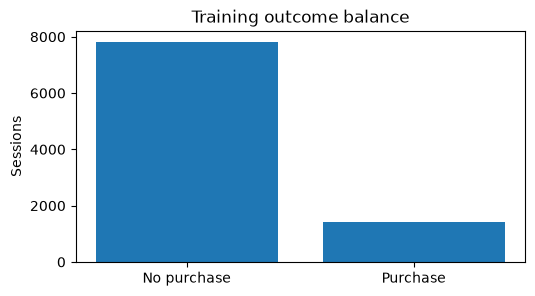

Majority-class accuracy would be 84.52%, with zero purchase sensitivity.


,median,zero %,skewness,buyer median,non-buyer median
Administrative,1.000,46.675,1.988,2.000,0.000
Administrative_Duration,8.000,47.648,5.716,54.800,0.000
Informational,0.000,78.642,4.191,0.000,0.000
Informational_Duration,0.000,80.545,7.801,0.000,0.000
ProductRelated,18.000,0.281,4.402,29.000,16.000
ProductRelated_Duration,598.250,6.175,8.228,1123.247,506.292
BounceRates,0.003,45.063,2.935,0.000,0.004
ExitRates,0.025,0.638,2.131,0.015,0.029
PageValues,0.000,77.744,6.251,17.536,0.000


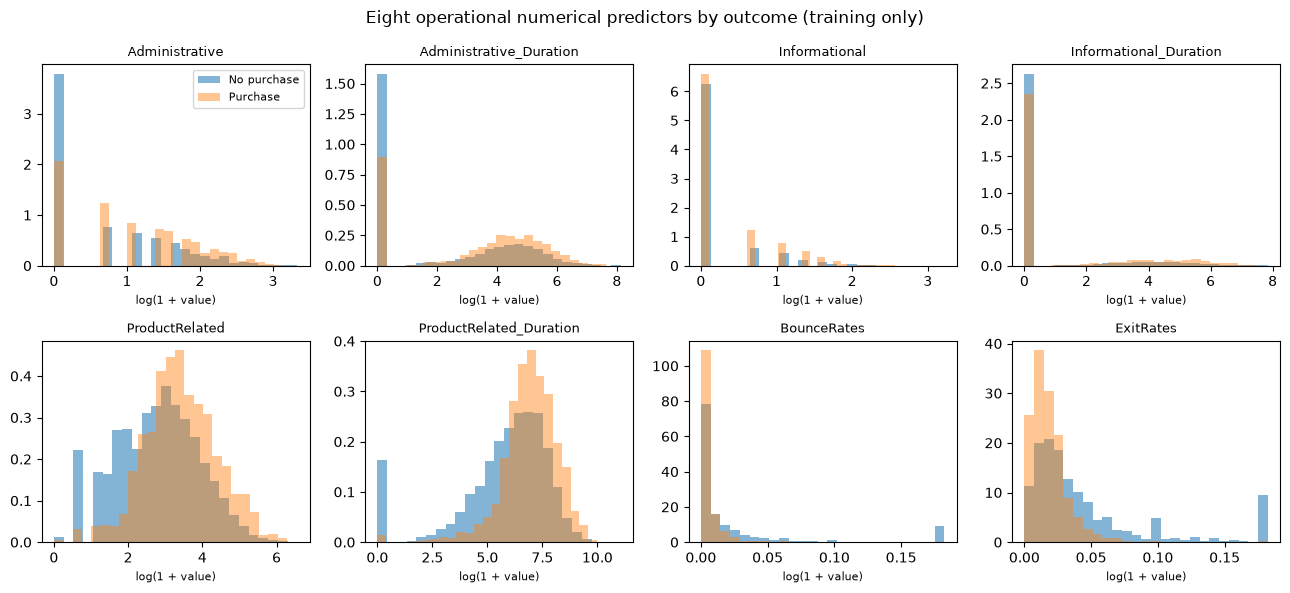

**Computed numerical finding.** The most skewed operational measure is `ProductRelated_Duration` (absolute skewness 8.23); the highest zero share is `Informational_Duration` (80.5%). This supports comparing fold-fitted transformations and zero indicators, while the CV results decide whether they improve prediction.

In [3]:
no_buy, buy = ytr.value_counts().reindex([0,1]).astype(int).values
fig, ax = plt.subplots(figsize=(5.8,3))
ax.bar(['No purchase','Purchase'],[no_buy,buy]); ax.set(title='Training outcome balance',ylabel='Sessions'); plt.show()
print(f'Majority-class accuracy would be {no_buy/len(ytr):.2%}, with zero purchase sensitivity.')
num_summary = pd.DataFrame({'median':Xtr[NUM_ALL].median(), 'zero %':100*(Xtr[NUM_ALL]==0).mean(),
    'skewness':Xtr[NUM_ALL].skew(), 'buyer median':Xtr.loc[ytr.eq(1),NUM_ALL].median(),
    'non-buyer median':Xtr.loc[ytr.eq(0),NUM_ALL].median()}).round(3)
display(num_summary)
fig, axes = plt.subplots(2,4,figsize=(13,6))
for ax,name in zip(axes.flat,NUM_SAFE):
    v=np.log1p(Xtr[name].clip(lower=0))
    ax.hist(v[ytr.eq(0)],bins=25,alpha=.55,density=True,label='No purchase')
    ax.hist(v[ytr.eq(1)],bins=25,alpha=.45,density=True,label='Purchase')
    ax.set_title(name,fontsize=9); ax.set_xlabel('log(1 + value)',fontsize=8)
axes.flat[0].legend(fontsize=8); plt.suptitle('Eight operational numerical predictors by outcome (training only)')
plt.tight_layout(); plt.show()
from IPython.display import Markdown
abs_skew=Xtr[NUM_SAFE].skew().abs().sort_values(ascending=False)
zero_rates=(Xtr[NUM_SAFE]==0).mean().sort_values(ascending=False)
display(Markdown(f"**Computed numerical finding.** The most skewed operational measure is `{abs_skew.index[0]}` (absolute skewness {abs_skew.iloc[0]:.2f}); the highest zero share is `{zero_rates.index[0]}` ({zero_rates.iloc[0]:.1%}). This supports comparing fold-fitted transformations and zero indicators, while the CV results decide whether they improve prediction."))


### Categorical EDA

**Objective and method.** Compare category frequencies and observed purchase rates for each training-only nominal predictor. Rates at rare levels are noisy and are descriptive, not evidence of a causal category effect. **Implication:** encode nominal codes with one-hot encoding inside each fold, and interpret sparse levels cautiously.

,levels,largest category %,purchase-rate range %
feature,,,
SpecialDay,6,89.596626,2.0–16.6
Month,10,27.576511,1.4–24.8
OperatingSystems,8,53.465989,10.7–25.0
Browser,13,64.420893,0.0–42.9
Region,9,38.088029,14.1–16.9
TrafficType,20,31.729209,0.0–33.3
VisitorType,3,85.541257,14.0–24.7
Weekend,2,76.954688,14.8–17.6


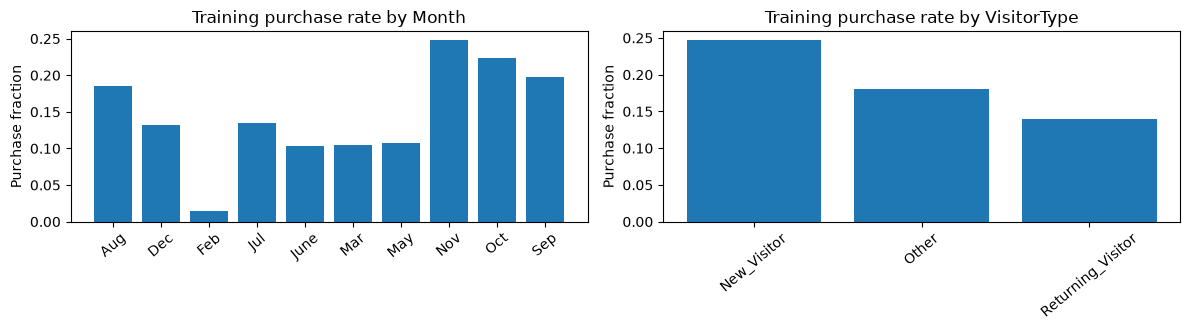

**Computed categorical finding.** `SpecialDay` has the most concentrated single level (89.6% of training sessions); `Browser` has the widest observed level purchase-rate range (42.9%). These descriptive differences motivate fold-safe one-hot encoding, while sparse level rates need cautious interpretation.

In [4]:
cat_summary=[]
for name in CAT_ALL:
    rates=pd.DataFrame({'level':Xtr[name],'purchase':ytr}).groupby('level').agg(
        sessions=('purchase','size'),purchase_rate=('purchase','mean')).sort_values('sessions',ascending=False)
    cat_summary.append({'feature':name,'levels':rates.shape[0],
        'largest category %':100*rates.sessions.max()/len(Xtr),
        'purchase-rate range %':f'{100*rates.purchase_rate.min():.1f}–{100*rates.purchase_rate.max():.1f}'})
display(pd.DataFrame(cat_summary).set_index('feature'))
fig,axs=plt.subplots(1,2,figsize=(12,3.4))
for ax,name in zip(axs,['Month','VisitorType']):
    p=pd.DataFrame({'category':Xtr[name],'purchase':ytr}).groupby('category').purchase.agg(['mean','size'])
    ax.bar(p.index,p['mean']); ax.set(title=f'Training purchase rate by {name}',ylabel='Purchase fraction')
    ax.tick_params(axis='x',rotation=40)
plt.tight_layout(); plt.show()
concentrations=pd.DataFrame(cat_summary).set_index('feature')
# Pick the category concentration maximum using the numeric summary rather than the formatted rate range.
dominant=max(CAT_ALL,key=lambda name:Xtr[name].value_counts(normalize=True).max())
rate_spread={name:pd.DataFrame({'x':Xtr[name],'y':ytr}).groupby('x').y.mean().max()-pd.DataFrame({'x':Xtr[name],'y':ytr}).groupby('x').y.mean().min() for name in CAT_ALL}
widest=max(rate_spread,key=rate_spread.get)
display(Markdown(f"**Computed categorical finding.** `{dominant}` has the most concentrated single level ({Xtr[dominant].value_counts(normalize=True).max():.1%} of training sessions); `{widest}` has the widest observed level purchase-rate range ({rate_spread[widest]:.1%}). These descriptive differences motivate fold-safe one-hot encoding, while sparse level rates need cautious interpretation."))


### EDA interpretation and next step

The computed training summaries above show the observed class balance, numeric skew/zero prevalence and categorical rate variation. We use stratification to preserve class proportions, test transforms and zero indicators through CV, and one-hot encode categories within folds. None of these associations identifies unique customers or estimates voucher response.

## 2. Pipelines and evaluation machinery

**Methodology.** Numeric imputation, optional transformations, scaling and one-hot category encoding are composed in an sklearn pipeline. For every candidate, one loop fits five fold-specific pipelines and records fold AUC and OOF probabilities from those same fits. Warnings are captured with their messages and summarized; they are not suppressed. Any fit or prediction failure is recorded in the ledger.

The first pass contains three all-17 designs. The bounded comparison has 20 attempted designs: three operational raw baselines, two existing raw mixed/numeric-only alternatives, six log1p/zero-indicator comparisons, two logistic interaction/subset variants, and four retained model-specific variants. The selected-model eligibility rule remains Logistic candidates, the existing raw mixed-likelihood Naive Bayes alternative, and the existing raw numeric-only LDA alternative. The classifier is selected by mean training-fold ROC-AUC; threshold analysis follows for the selected model.

In [5]:
class LogAndZeroIndicators(BaseEstimator, TransformerMixin):
    def fit(self,X,y=None):
        A=np.asarray(X,float); self.zero_columns_=np.flatnonzero((A==0).mean(axis=0)>=.50); return self
    def transform(self,X):
        A=np.asarray(X,float)
        return np.column_stack([np.log1p(np.maximum(A,0)),(A[:,self.zero_columns_]>0).astype(float)])
class ColumnSubset(BaseEstimator, TransformerMixin):
    def __init__(self,columns): self.columns=columns
    def fit(self,X,y=None): return self
    def transform(self,X): return X.loc[:,self.columns].copy()

class ReservedCategoryEncoder(BaseEstimator, TransformerMixin):
    """Learn nominal maps on fold training data; reserve code 0 for unseen validation levels."""
    def fit(self,X,y=None):
        A=np.asarray(X,dtype=object)
        self.maps_=[]
        for j in range(A.shape[1]):
            levels=sorted({str(v) for v in A[:,j]})
            self.maps_.append({level:i+1 for i,level in enumerate(levels)})
        return self
    def transform(self,X):
        A=np.asarray(X,dtype=object)
        out=np.zeros(A.shape,dtype=np.int64)
        for j,mapping in enumerate(self.maps_):
            out[:,j]=[mapping.get(str(v),0) for v in A[:,j]]
        return out

class MixedNaiveBayes(ClassifierMixin, BaseEstimator):
    """Combine Gaussian numeric and smoothed categorical nominal likelihoods."""
    def __init__(self,n_numeric,n_categorical,alpha=1.0):
        self.n_numeric=n_numeric; self.n_categorical=n_categorical; self.alpha=alpha
    def fit(self,X,y):
        A=np.asarray(X,dtype=float)
        numeric=A[:,:self.n_numeric]
        categorical=np.rint(A[:,self.n_numeric:self.n_numeric+self.n_categorical]).astype(np.int64)
        self.numeric_model_=GaussianNB().fit(numeric,y)
        # Reserve category 0 in each feature support; alpha smoothing gives unseen levels finite likelihood.
        min_categories=np.maximum(categorical.max(axis=0)+1,2)
        self.categorical_model_=CategoricalNB(alpha=self.alpha,min_categories=min_categories).fit(categorical,y)
        self.classes_=self.numeric_model_.classes_
        if not np.array_equal(self.classes_,self.categorical_model_.classes_):
            raise ValueError('Numeric and categorical likelihood models learned different class sets.')
        self.class_prior_=self.numeric_model_.class_prior_
        return self
    def predict_log_proba(self,X):
        A=np.asarray(X,dtype=float)
        numeric=A[:,:self.n_numeric]
        categorical=np.rint(A[:,self.n_numeric:self.n_numeric+self.n_categorical]).astype(np.int64)
        # Both public methods include the class prior; remove one duplicate prior, then normalize.
        joint=(self.numeric_model_.predict_log_proba(numeric)
               + self.categorical_model_.predict_log_proba(categorical)
               - np.log(self.class_prior_)[None,:])
        return joint-logsumexp(joint,axis=1,keepdims=True)
    def predict_proba(self,X):
        return np.exp(self.predict_log_proba(X))
    def predict(self,X):
        return self.classes_[np.argmax(self.predict_log_proba(X),axis=1)]

def _numeric_steps(numeric_transform='raw',scale=True):
    steps=[('impute',SimpleImputer(strategy='median'))]
    transforms={'log1p':FunctionTransformer(np.log1p,validate=False),
        'zeroind':LogAndZeroIndicators()}
    if numeric_transform in transforms: steps.append(('transform',transforms[numeric_transform]))
    elif numeric_transform!='raw': raise ValueError('Unknown numeric transform: '+numeric_transform)
    if scale: steps.append(('scale',StandardScaler()))
    return steps

def build_numeric_only(model,numeric_transform='raw'):
    return Pipeline([('subset',ColumnSubset(NUM_SAFE)),
        ('pre',Pipeline(_numeric_steps(numeric_transform,scale=True))),('clf',clone(model))])

def build_mixed_nb(numeric_transform='raw'):
    pre=ColumnTransformer([
        # Fold-fitted standardization prevents GaussianNB's shared var_smoothing from being
        # dominated by duration-valued features; affine scaling preserves the Gaussian form.
        ('numeric',Pipeline(_numeric_steps(numeric_transform,scale=True)),NUM_SAFE),
        ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                                 ('encode',ReservedCategoryEncoder())]),CAT_ALL)],
        remainder='drop',sparse_threshold=0.0)
    return Pipeline([('subset',ColumnSubset(SAFE)),('pre',pre),
                     ('clf',MixedNaiveBayes(len(NUM_SAFE),len(CAT_ALL),alpha=1.0))])

def build(model,columns,numeric_transform='raw',poly=False):
    nums=[c for c in NUM_ALL if c in columns]; cats=[c for c in CAT_ALL if c in columns]
    # Impute and transform numeric values, form interactions if requested, then scale.
    numeric=_numeric_steps(numeric_transform,scale=False)
    if poly: numeric.append(('interactions',PolynomialFeatures(degree=2,interaction_only=True,include_bias=False)))
    numeric.append(('scale',StandardScaler()))
    pre=ColumnTransformer([('numeric',Pipeline(numeric),nums),('categorical',Pipeline([
        ('impute',SimpleImputer(strategy='most_frequent')),
        ('encode',OneHotEncoder(handle_unknown='ignore',drop='first',sparse_output=False))]),cats)],
        remainder='drop',sparse_threshold=0.0)
    return Pipeline([('subset',ColumnSubset(list(columns))),('pre',pre),('clf',clone(model))])

def confusion_rates(y_true,prob,t=.5):
    tn,fp,fn,tp=confusion_matrix(y_true,np.asarray(prob)>=t,labels=[0,1]).ravel()
    return {'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
        'sensitivity':tp/(tp+fn) if tp+fn else np.nan,
        'specificity':tn/(tn+fp) if tn+fp else np.nan}
def revenue_at(y_true,prob,t):
    r=confusion_rates(y_true,prob,t)
    r0=r['TP']+r['FN']; rm=r['TP']+.80*(r['FN']+r['TN'])
    delta=rm-r0
    return {**r,'R0_A':float(r0),'Rmodel_A':float(rm),'delta_A':float(delta),
        'relative_lift':float(delta/r0) if r0 else np.nan,'voucher_count':r['FN']+r['TN'],
        'weighted_opportunity_cost_A':float(.80*r['FP']+.20*r['FN'])}
MODELS={'Logistic':LogisticRegression(max_iter=3000),'Gaussian NB':GaussianNB(),
        'LDA':LinearDiscriminantAnalysis()}
CONFIGS={}; RESULTS={}; LEDGER=[]
def evaluate(label,model,columns,transform='raw',poly=False,stage='candidate',pipeline=None):
    if label in CONFIGS: raise ValueError('Duplicate candidate label: '+label)
    pipe=pipeline if pipeline is not None else build(model,columns,transform,poly); CONFIGS[label]=pipe
    oof=np.full(len(Xtr),np.nan); fold_auc=[]; fold_ap=[]; warning_records=[]; failure=''
    try:
        for fold,(fit_idx,val_idx) in enumerate(FOLDS.split(Xtr,ytr),start=1):
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                try:
                    fitted=clone(pipe).fit(Xtr.iloc[fit_idx],ytr.iloc[fit_idx])
                    pred=fitted.predict_proba(Xtr.iloc[val_idx])[:,1]
                finally:
                    for w in caught:
                        warning_records.append({'fold':fold,'category':w.category.__name__,'message':str(w.message)[:240]})
            if not np.all(np.isfinite(pred)): raise ValueError(f'non-finite predictions in fold {fold}')
            oof[val_idx]=pred
            fold_auc.append(roc_auc_score(ytr.iloc[val_idx],pred))
            fold_ap.append(average_precision_score(ytr.iloc[val_idx],pred))
        if np.isnan(oof).any(): raise ValueError('some training rows lack an OOF prediction')
        RESULTS[label]={'oof':oof,'fold_auc':np.asarray(fold_auc),'fold_ap':np.asarray(fold_ap),
                        'pooled_oof_ap':average_precision_score(ytr,oof),'warnings':warning_records}
        row={'stage':stage,'candidate':label,'mean_fold_auc':float(np.mean(fold_auc)),
             'fold_auc_sd':float(np.std(fold_auc,ddof=1)),'mean_fold_ap':float(np.mean(fold_ap)),
             'fold_ap_sd':float(np.std(fold_ap,ddof=1)),
             'pooled_oof_ap':float(average_precision_score(ytr,oof)),
             'status':'OK','warning_count':len(warning_records),'failure':''}
    except Exception as exc:
        failure=f'{type(exc).__name__}: {str(exc).splitlines()[0][:220]}'
        row={'stage':stage,'candidate':label,'mean_fold_auc':np.nan,'fold_auc_sd':np.nan,
             'mean_fold_ap':np.nan,'fold_ap_sd':np.nan,'pooled_oof_ap':np.nan,
             'status':'FAILED','warning_count':len(warning_records),'failure':failure}
        RESULTS[label]={'warnings':warning_records,'failure':failure}
    LEDGER.append(row)
    return row
print('Families:',', '.join(MODELS))

Families: Logistic, Gaussian NB, LDA


## 3. First pass: all 17 predictors

**Objective.** Follow the professor's instruction before changing predictor sets or model forms. **Method:** run the three default classifiers with technical one-hot encoding for nominal inputs; retain warnings and actual failures. These diagnostic fits are not candidates for operational selection because `PageValues` may be unavailable at decision time.

In [6]:
for name,estimator in MODELS.items():
    evaluate(f'ALL17 | {name}',estimator,ALL,stage='first pass all 17')
FIRST_PASS=pd.DataFrame(LEDGER).query("stage == 'first pass all 17'")
display(FIRST_PASS.set_index('candidate').round(4))

,stage,mean_fold_auc,fold_auc_sd,mean_fold_ap,fold_ap_sd,pooled_oof_ap,status,warning_count,failure
candidate,,,,,,,,,
ALL17 | Logistic,first pass all 17,0.8947,0.0066,0.6494,0.0156,0.6483,OK,3,
ALL17 | Gaussian NB,first pass all 17,0.6986,0.0753,0.2623,0.0793,0.2371,OK,3,
ALL17 | LDA,first pass all 17,0.9005,0.0039,0.6478,0.0116,0.6460,OK,3,


The table is generated from this runtime. A warning and a fit failure are distinct outcomes: a warning means the estimator returned predictions with a numerical concern; a failure means the fold could not produce a result. The ledger preserves the actual warnings and failures from the installed library.

In [7]:
def warning_table(labels=None):
    rows=[]
    for label,result in RESULTS.items():
        if labels is not None and label not in labels: continue
        by={}
        for w in result.get('warnings',[]):
            key=(w['category'],w['message']); by[key]=by.get(key,0)+1
        for (category,message),count in by.items():
            rows.append({'candidate':label,'fold warnings':count,'warning type':category,'message':message})
    return pd.DataFrame(rows,columns=['candidate','fold warnings','warning type','message'])
first_labels=set(FIRST_PASS.candidate)
warns=warning_table(first_labels)
print('First-pass failures:')
display(FIRST_PASS.loc[FIRST_PASS.status.eq('FAILED'),['candidate','failure']])
print('First-pass warning details (repeated identical messages are grouped):')
display(warns)

First-pass failures:


,candidate,failure


First-pass warning details (repeated identical messages are grouped):


,candidate,fold warnings,warning type,message
0,ALL17 | Logistic,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
1,ALL17 | Logistic,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
2,ALL17 | Gaussian NB,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
3,ALL17 | Gaussian NB,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
4,ALL17 | LDA,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
5,ALL17 | LDA,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros


## 4. PageValues timing and operational baseline

**Objective.** Compare a training-only first-pass result with and without `PageValues`, then define the operational predictor set. **Interpretation:** an AUC difference is an association, not proof of leakage. The substantive concern is that this Google Analytics value may depend on completed-session information and may not exist when a voucher decision must be made. The 16 operational predictors therefore exclude it.

In [8]:
first_log=RESULTS.get('ALL17 | Logistic',{})
page_row=evaluate('Operational16 | Logistic raw',MODELS['Logistic'],SAFE,stage='operational raw baseline')
if first_log.get('fold_auc') is not None and page_row['status']=='OK':
    print(f"Logistic mean fold AUC with PageValues: {np.mean(first_log['fold_auc']):.4f}")
    print(f"Logistic mean fold AUC without PageValues: {page_row['mean_fold_auc']:.4f}")
    print(f"Difference (with minus without): {np.mean(first_log['fold_auc'])-page_row['mean_fold_auc']:+.4f}")
display(pd.crosstab(Xtr['PageValues'].gt(0),ytr,normalize='columns').rename(
    index={False:'PageValues = 0',True:'PageValues > 0'},columns={0:'Non-buyers',1:'Buyers'}).round(3))
print('Operational policy models exclude PageValues on timing/availability grounds.')

Logistic mean fold AUC with PageValues: 0.8947
Logistic mean fold AUC without PageValues: 0.7541
Difference (with minus without): +0.1406


Revenue,Non-buyers,Buyers
PageValues,,
PageValues = 0,0.886,0.182
PageValues > 0,0.114,0.818


Operational policy models exclude PageValues on timing/availability grounds.


## 5. Operational16 raw baselines

**Methodology.** Evaluate Logistic Regression, Gaussian Naive Bayes and LDA on the same five folds, alongside the Logistic raw baseline already fit during the `PageValues` comparison. This completes the raw comparison; no transformation or tuning is introduced until the assumption diagnostics below have been reviewed.


In [9]:
BASELINE_LABELS={}
for name,estimator in MODELS.items():
    label=f'Operational16 | {name} raw'
    row=page_row if name=='Logistic' else evaluate(label,estimator,SAFE,stage='operational raw baseline')
    if row['status']=='OK': BASELINE_LABELS[name]=label


### Legacy operational baselines with one-hot categories

**Objective and method.** Preserve the three Operational16 raw comparisons from the existing 29-design analysis. Logistic Regression accepts one-hot nominal predictors directly. Gaussian Naive Bayes and LDA applied to these binary indicators are retained as approximate diagnostic baselines because their Gaussian likelihood assumptions do not match one-hot variables. Their mean-fold and pooled OOF AUC/AP, threshold rates and confusion counts remain visible, but these configurations are excluded from final model/threshold eligibility. The mixed-predictor alternatives below provide a defensible Naive Bayes likelihood; the existing numeric-only LDA alternative provides a justified discriminant-analysis reference.


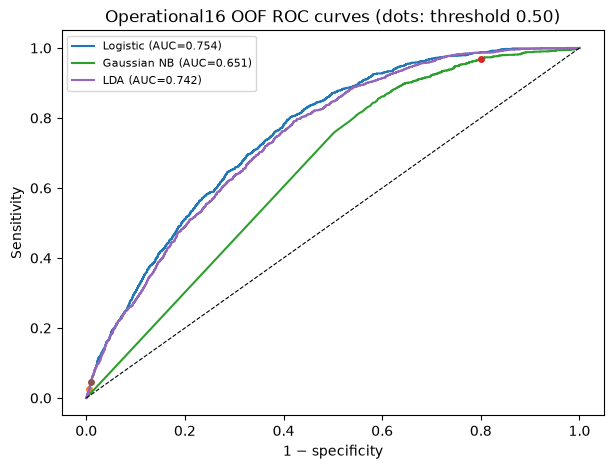

,candidate,mean fold AUC,fold AUC SD,pooled OOF AUC,mean fold AP,fold AP SD,pooled OOF AP,sensitivity @ .5,specificity @ .5,TP,FP,FN,TN
family,,,,,,,,,,,,,
Logistic,Operational16 | Logistic raw,0.7541,0.0217,0.7540,0.3287,0.0335,0.3237,0.0252,0.9940,36,47,1395,7769
Gaussian NB,Operational16 | Gaussian NB raw,0.6606,0.0513,0.6510,0.2249,0.0391,0.2124,0.9693,0.1997,1387,6255,44,1561
LDA,Operational16 | LDA raw,0.7424,0.0201,0.7422,0.3168,0.0230,0.3125,0.0454,0.9900,65,78,1366,7738


Logistic confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):


,Predicted 0,Predicted 1
Actual 0,7769,47
Actual 1,1395,36


Gaussian NB confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):


,Predicted 0,Predicted 1
Actual 0,1561,6255
Actual 1,44,1387


LDA confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):


,Predicted 0,Predicted 1
Actual 0,7738,78
Actual 1,1366,65


In [10]:
baseline_rows=[]
fig,ax=plt.subplots(figsize=(7,5))
for family,label in BASELINE_LABELS.items():
    if label not in RESULTS or 'oof' not in RESULTS[label]: continue
    prob=RESULTS[label]['oof']; rates=confusion_rates(ytr,prob,.5)
    baseline_rows.append({'family':family,'candidate':label,
        'mean fold AUC':np.mean(RESULTS[label]['fold_auc']),'fold AUC SD':np.std(RESULTS[label]['fold_auc'],ddof=1),'pooled OOF AUC':roc_auc_score(ytr,prob),
        'mean fold AP':np.mean(RESULTS[label]['fold_ap']),'fold AP SD':np.std(RESULTS[label]['fold_ap'],ddof=1),'pooled OOF AP':average_precision_score(ytr,prob),
        'sensitivity @ .5':rates['sensitivity'],
        'specificity @ .5':rates['specificity'],**{k:rates[k] for k in ['TP','FP','FN','TN']}})
    fpr,tpr,_=roc_curve(ytr,prob); ax.plot(fpr,tpr,label=f'{family} (AUC={roc_auc_score(ytr,prob):.3f})')
    ax.plot(1-rates['specificity'],rates['sensitivity'],'o',ms=4)
ax.plot([0,1],[0,1],'k--',lw=.8); ax.set(xlabel='1 − specificity',ylabel='Sensitivity',title='Operational16 OOF ROC curves (dots: threshold 0.50)')
ax.legend(fontsize=8); plt.show()
BASELINES=pd.DataFrame(baseline_rows).set_index('family'); display(BASELINES.round(4))
for row in baseline_rows:
    print(f"{row['family']} confusion matrix at 0.50 (rows actual 0/1; columns predicted 0/1):")
    display(pd.DataFrame([[row['TN'],row['FP']],[row['FN'],row['TP']]],index=['Actual 0','Actual 1'],columns=['Predicted 0','Predicted 1']))


**Training-only diagnostics.** Numerical skew and within-class dependence are checked to explain why alternatives were considered, not to claim assumptions are fully satisfied. Large skew supports testing log transformations; correlated predictors challenge Gaussian Naive Bayes independence and may affect covariance estimates in discriminant analysis. The CV comparison, not the diagnostic alone, determines whether a modification is useful.

### Assumption diagnostics before modifications

**Objective and method.** Use training-only descriptive checks to explain the planned modifications: Q–Q plots for representative numerical predictors within each class (normality), class-specific numerical covariance summaries (shared-covariance assumption), correlations/condition number (independence and multicollinearity), and marginal binned empirical logits for two predictors (a visual shape check, not a formal conditional logit-linearity test). These checks are diagnostics, not formal proof of estimator validity. The full design also includes nominal categories, so numeric-only covariance summaries cannot certify multivariate normality of the encoded full feature space.


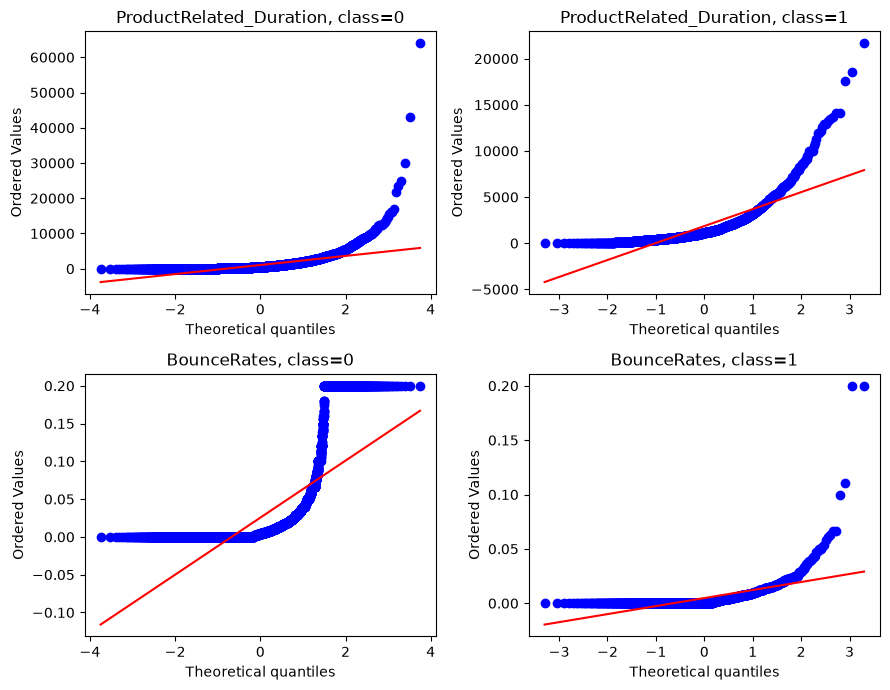

,trace,largest eigenvalue,smallest eigenvalue,condition number
class,,,,
0,3366246.229,3323621.275,0.0,1.564269e+10
1,4957046.204,4894291.732,0.0,1.107012e+11


,mean_x,n,p,empirical_logit
bin,,,,
"(-0.001, 34.5]",7.266,926,0.028,-3.526
"(34.5, 126.533]",77.631,924,0.050,-2.939
"(126.533, 244.0]",181.967,925,0.058,-2.772
"(244.0, 398.98]",316.863,924,0.120,-1.987
"(398.98, 598.25]",495.895,925,0.173,-1.562
"(598.25, 850.283]",718.777,924,0.192,-1.438
"(850.283, 1227.871]",1028.742,925,0.219,-1.267
"(1227.871, 1775.135]",1475.628,924,0.189,-1.452
"(1775.135, 2861.087]",2237.861,925,0.229,-1.211


,mean_x,n,p,empirical_logit
bin,,,,
"(-0.001, 0.00741]",0.004,937,0.293,-0.877
"(0.00741, 0.012]",0.010,913,0.256,-1.064
"(0.012, 0.0161]",0.014,924,0.251,-1.091
"(0.0161, 0.0205]",0.018,925,0.210,-1.325
"(0.0205, 0.0251]",0.023,925,0.194,-1.425
"(0.0251, 0.0325]",0.029,924,0.148,-1.745
"(0.0325, 0.0417]",0.037,946,0.106,-2.131
"(0.0417, 0.0591]",0.049,903,0.053,-2.870
"(0.0591, 0.1]",0.080,1008,0.028,-3.538


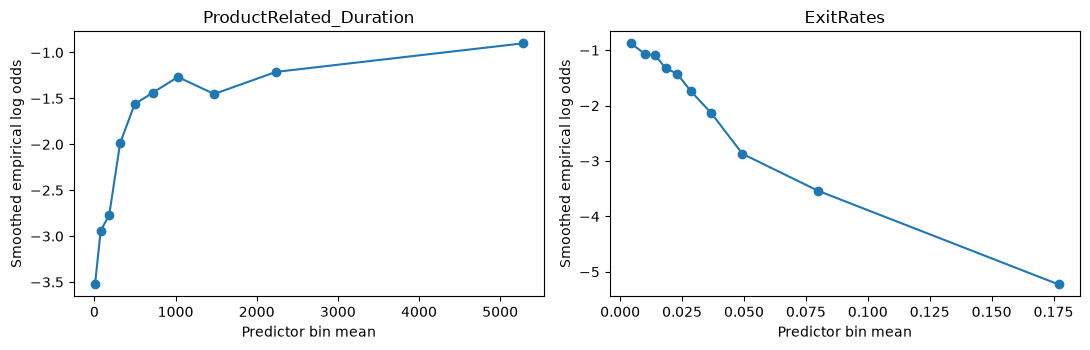

In [11]:
from scipy.stats import probplot
fig,axes=plt.subplots(2,2,figsize=(9,7))
for row,(feature,outcome) in enumerate([('ProductRelated_Duration',0),('ProductRelated_Duration',1),('BounceRates',0),('BounceRates',1)]):
    values=Xtr.loc[ytr.eq(outcome),feature].to_numpy()
    probplot(values,dist='norm',plot=axes[row//2,row%2])
    axes[row//2,row%2].set_title(f'{feature}, class={outcome}')
plt.tight_layout(); plt.show()

class_cov=[]
for outcome in (0,1):
    cov=Xtr.loc[ytr.eq(outcome),NUM_SAFE].cov().to_numpy()
    eig=np.linalg.eigvalsh(cov)
    class_cov.append({'class':outcome,'trace':np.trace(cov),'largest eigenvalue':eig.max(),
                      'smallest eigenvalue':eig.min(),'condition number':eig.max()/max(eig.min(),1e-15)})
display(pd.DataFrame(class_cov).set_index('class').round(3))

fig,axes=plt.subplots(1,2,figsize=(11,3.6))
for ax,feature in zip(axes,['ProductRelated_Duration','ExitRates']):
    bins=pd.qcut(Xtr[feature],q=10,duplicates='drop')
    tab=pd.DataFrame({'bin':bins,'y':ytr,'x':Xtr[feature]}).groupby('bin',observed=True).agg(
        mean_x=('x','mean'),n=('y','size'),p=('y','mean'))
    tab['empirical_logit']=np.log((tab.p*tab.n+0.5)/((1-tab.p)*tab.n+0.5))
    display(tab.round(3))
    ax.plot(tab.mean_x,tab.empirical_logit,'o-')
    ax.set(title=feature,xlabel='Predictor bin mean',ylabel='Smoothed empirical log odds')
plt.tight_layout(); plt.show()


In [12]:
assumption_rows=[]
for col in NUM_SAFE:
    for outcome in (0,1):
        arr=Xtr.loc[ytr.eq(outcome),col].to_numpy()
        assumption_rows.append({'variable':col,'class':outcome,'skew':stats.skew(arr),'zero %':100*np.mean(arr==0)})
ASSUMPTIONS=pd.DataFrame(assumption_rows)
display(ASSUMPTIONS.pivot(index='variable',columns='class',values=['skew','zero %']).round(2))
abs_skew=Xtr[NUM_SAFE].skew().abs().sort_values(ascending=False)
# Pairwise dependence and a scale-normalized covariance comparison use the continuous numeric predictors only.
corr_summaries={}
for outcome in (0,1):
    corr=Xtr.loc[ytr.eq(outcome),NUM_SAFE].corr()
    pairs=corr.abs().where(~np.eye(len(corr),dtype=bool)).stack().sort_values(ascending=False)
    corr_summaries[outcome]=(pairs.index[0],float(pairs.iloc[0]))
    print(f'Class {outcome}: largest absolute numeric correlation {pairs.index[0]} = {pairs.iloc[0]:.3f}')
num_corr=Xtr[NUM_SAFE].corr().to_numpy()
condition=np.linalg.cond(num_corr)
cov0=Xtr.loc[ytr.eq(0),NUM_SAFE].cov().to_numpy(); cov1=Xtr.loc[ytr.eq(1),NUM_SAFE].cov().to_numpy()
pooled_std=Xtr[NUM_SAFE].std().to_numpy(); scale=np.diag(1/pooled_std)
scaled_cov_difference=np.linalg.norm(scale@(cov1-cov0)@scale,ord='fro')
print(f'Scaled numeric correlation-matrix condition number: {condition:.2f}')
print(f'Scale-normalized Frobenius difference between class covariance matrices: {scaled_cov_difference:.3f}')
display(Markdown(f"""
**Computed assumption findings.** `{abs_skew.index[0]}` has the largest absolute training skewness ({abs_skew.iloc[0]:.2f}); the strongest within-class numeric correlation is `{corr_summaries[0][0]}` for non-buyers ({corr_summaries[0][1]:.2f}) and `{corr_summaries[1][0]}` for buyers ({corr_summaries[1][1]:.2f}). The scale-normalized covariance difference is {scaled_cov_difference:.2f}; the raw covariance condition numbers above are sensitive to measurement scales, so the normalized comparison is more interpretable. The empirical-logit and Q–Q plots assess shape visually. These numerical-only diagnostics suggest departures from normality, independence and equal covariance, but cannot establish assumptions for the full mixed, one-hot encoded predictor space. We therefore test log transformations, zero indicators, interactions and retained regularisation variants inside CV after completing this diagnostic stage.
"""))


skew       zero %       
class                        0     1      0      1
variable                                          
Administrative            2.16  1.37  50.47  25.93
Administrative_Duration   6.29  3.81  51.37  27.32
BounceRates               2.65  8.72  43.16  55.49
ExitRates                 1.92  3.62   0.38   2.03
Informational             4.62  2.80  80.64  67.71
Informational_Duration    8.69  4.87  82.43  70.23
ProductRelated            4.80  3.25   0.31   0.14
ProductRelated_Duration  10.08  3.09   7.20   0.56

Class 0: largest absolute numeric correlation ('ExitRates', 'BounceRates') = 0.914
Class 1: largest absolute numeric correlation ('ProductRelated', 'ProductRelated_Duration') = 0.899
Scaled numeric correlation-matrix condition number: 42.22
Scale-normalized Frobenius difference between class covariance matrices: 2.851



**Computed assumption findings.** `ProductRelated_Duration` has the largest absolute training skewness (8.23); the strongest within-class numeric correlation is `('ExitRates', 'BounceRates')` for non-buyers (0.91) and `('ProductRelated', 'ProductRelated_Duration')` for buyers (0.90). The scale-normalized covariance difference is 2.85; the raw covariance condition numbers above are sensitive to measurement scales, so the normalized comparison is more interpretable. The empirical-logit and Q–Q plots assess shape visually. These numerical-only diagnostics suggest departures from normality, independence and equal covariance, but cannot establish assumptions for the full mixed, one-hot encoded predictor space. We therefore test log transformations, zero indicators, interactions and retained regularisation variants inside CV after completing this diagnostic stage.


## 6. Mixed-likelihood and numeric-only reference specifications

**Objective.** Retain the existing raw mixed Gaussian/Categorical Naive Bayes and raw numeric-only LDA alternatives as eligible operational references. The log1p and zeroind comparisons below remain the existing one-hot GaussianNB/LDA diagnostics and are not promoted to eligibility.

**Methodology.** Mixed Naive Bayes combines Gaussian numeric likelihoods and smoothed categorical likelihoods, with fold-fitted category maps. Numeric-only LDA uses the eight operational numerical predictors and omits nominal predictors; this trade-off is reported explicitly. No transformed mixed-likelihood or numeric-only variants are added.

**Implementation and implication.** The following cell evaluates only those two existing raw specifications on the same five folds, then displays OOF curves and metrics.

Additional mixed/numeric-only designs: 2 | successful: 2


,stage,candidate,mean_fold_auc,fold_auc_sd,mean_fold_ap,fold_ap_sd,pooled_oof_ap,status,warning_count,failure
0,mixed likelihood baseline,Mixed NB | Gaussian numeric + categorical nominal raw,0.7314,0.0215,0.2816,0.0238,0.2772,OK,0,
1,numeric-only discriminant baseline,Numeric8 | LDA raw,0.7171,0.0229,0.2807,0.0275,0.2763,OK,0,


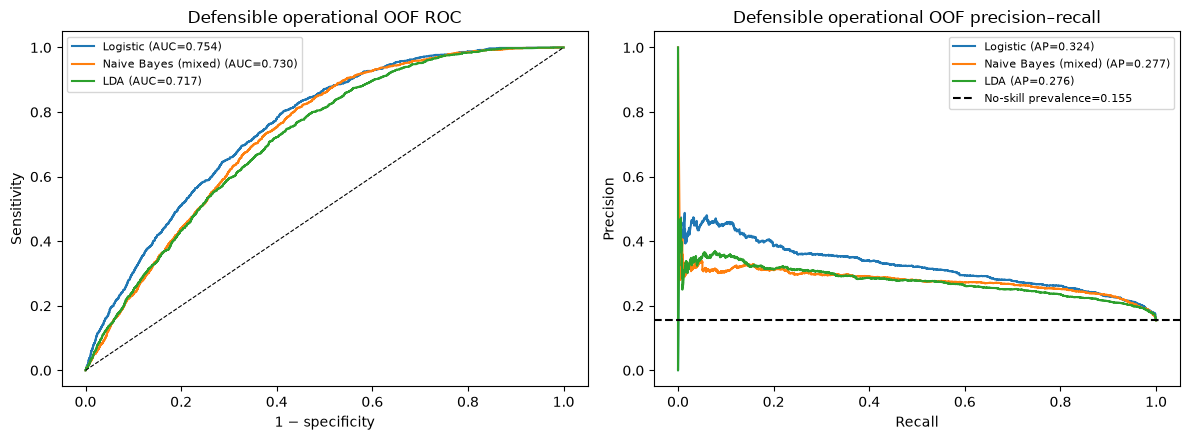

,specification,mean CV AUC,CV AUC SD,pooled OOF AUC,mean CV AP,CV AP SD,pooled OOF AP,sensitivity @ .5,specificity @ .5,TP,FP,FN,TN
family,,,,,,,,,,,,,
Logistic,Operational16 | Logistic raw,0.7541,0.0217,0.7540,0.3287,0.0335,0.3237,0.0252,0.9940,36,47,1395,7769
Naive Bayes (mixed),Mixed NB | Gaussian numeric + categorical nominal raw,0.7314,0.0215,0.7305,0.2816,0.0238,0.2772,0.6115,0.7024,875,2326,556,5490
LDA,Numeric8 | LDA raw,0.7171,0.0229,0.7167,0.2807,0.0275,0.2763,0.0091,0.9955,13,35,1418,7781


In [13]:
MIXED_NB_RAW='Mixed NB | Gaussian numeric + categorical nominal raw'
NUM_LDA_RAW='Numeric8 | LDA raw'
NEW_MODEL_ROWS=[]
NEW_MODEL_ROWS.append(evaluate(MIXED_NB_RAW,MODELS['Gaussian NB'],SAFE,stage='mixed likelihood baseline',pipeline=build_mixed_nb('raw')))
NEW_MODEL_ROWS.append(evaluate(NUM_LDA_RAW,MODELS['LDA'],NUM_SAFE,stage='numeric-only discriminant baseline',pipeline=build_numeric_only(MODELS['LDA'],'raw')))
NEW_MODEL_CANDIDATES=[row['candidate'] for row in NEW_MODEL_ROWS if row['status']=='OK']
print('Additional mixed/numeric-only designs:',len(NEW_MODEL_ROWS),'| successful:',len(NEW_MODEL_CANDIDATES))
display(pd.DataFrame(NEW_MODEL_ROWS).round(4))

DEFENSIBLE_BASELINES={
    'Logistic':'Operational16 | Logistic raw',
    'Naive Bayes (mixed)':MIXED_NB_RAW,
    'LDA':NUM_LDA_RAW}
reference_rows=[]
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for family,label in DEFENSIBLE_BASELINES.items():
    if 'oof' not in RESULTS.get(label,{}):
        print(f'No successful defensible baseline for {family}:',RESULTS.get(label,{}).get('failure','unavailable'))
        continue
    res=RESULTS[label]; prob=res['oof']; rates=confusion_rates(ytr,prob,.5)
    reference_rows.append({'family':family,'specification':label,
        'mean CV AUC':np.mean(res['fold_auc']),'CV AUC SD':np.std(res['fold_auc'],ddof=1),
        'pooled OOF AUC':roc_auc_score(ytr,prob),'mean CV AP':np.mean(res['fold_ap']),
        'CV AP SD':np.std(res['fold_ap'],ddof=1),'pooled OOF AP':average_precision_score(ytr,prob),
        'sensitivity @ .5':rates['sensitivity'],
        'specificity @ .5':rates['specificity'],**{k:rates[k] for k in ['TP','FP','FN','TN']}})
    fpr,tpr,_=roc_curve(ytr,prob); axes[0].plot(fpr,tpr,label=f'{family} (AUC={roc_auc_score(ytr,prob):.3f})')
    precision,recall,_=precision_recall_curve(ytr,prob)
    axes[1].plot(recall,precision,label=f'{family} (AP={average_precision_score(ytr,prob):.3f})')
axes[0].plot([0,1],[0,1],'k--',lw=.8); axes[0].set(xlabel='1 − specificity',ylabel='Sensitivity',title='Defensible operational OOF ROC')
axes[1].axhline(ytr.mean(),color='black',ls='--',label=f'No-skill prevalence={ytr.mean():.3f}')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Defensible operational OOF precision–recall')
for ax in axes: ax.legend(fontsize=8,loc='best')
plt.tight_layout(); plt.show()
DEFENSIBLE_BASELINE_TABLE=pd.DataFrame(reference_rows).set_index('family')
display(DEFENSIBLE_BASELINE_TABLE.round(4))


### Bounded CV-guided improvements

**Methodology.** The design ledger contains 20 attempted designs, with six log1p/zeroind comparisons across the three required classifiers, two logistic interaction/subset alternatives, and four retained model-specific variants. One-hot GaussianNB and LDA transformation comparisons are diagnostics; final eligibility remains Logistic candidates plus the existing raw mixed NB and raw numeric-only LDA alternatives. All preprocessing is fit inside each fold.

In [14]:
LEGACY_CANDIDATES={name:label for name,label in BASELINE_LABELS.items()}
CANDIDATES={}
for transform in ['log1p','zeroind']:
    for name in ['Logistic','Gaussian NB','LDA']:
        label=f'{name} | {transform}'
        row=evaluate(label,MODELS[name],SAFE,transform,stage='transformation')
        if row['status']=='OK': LEGACY_CANDIDATES[label]=label
five=['ExitRates','ProductRelated_Duration','Month','TrafficType','VisitorType']
for label,model,columns,transform,poly in [
    ('Logistic | raw interactions',MODELS['Logistic'],SAFE,'raw',True),
    ('Logistic | five original predictors',MODELS['Logistic'],five,'raw',False)]:
    row=evaluate(label,model,columns,transform,poly,stage='nonlinearity or subset')
    if row['status']=='OK': LEGACY_CANDIDATES[label]=label
for label,model,transform in [
    ('Logistic | L2 C=0.1',LogisticRegression(C=.1,max_iter=3000),'raw'),
    ('Logistic | L2 C=10',LogisticRegression(C=10,max_iter=3000),'raw'),
    ('Gaussian NB | smoother',GaussianNB(var_smoothing=1e-5),'raw'),
    ('LDA | shrinkage',LinearDiscriminantAnalysis(solver='lsqr',shrinkage='auto'),'raw')]:
    row=evaluate(label,model,SAFE,transform,stage='model-specific tuning')
    if row['status']=='OK': LEGACY_CANDIDATES[label]=label
LED=pd.DataFrame(LEDGER)
# Only Logistic variants plus the two existing raw likelihood alternatives are selection-eligible.
CANDIDATES={label:label for label in LEGACY_CANDIDATES.values()
    if label.startswith('Operational16 | Logistic') or label.startswith('Logistic |')}
for label in NEW_MODEL_CANDIDATES: CANDIDATES[label]=label
print(f'Candidate designs recorded: {len(LED)} (expected 20); successful eligible operational candidates: {len(CANDIDATES)}')
display(LED[['stage','candidate','mean_fold_auc','fold_auc_sd','mean_fold_ap','fold_ap_sd','pooled_oof_ap','status','warning_count','failure']].round(4))
print('Warnings recorded across all attempted candidate fits (identical messages grouped):')
display(warning_table())

Candidate designs recorded: 20 (expected 20); successful eligible operational candidates: 9


,stage,candidate,mean_fold_auc,fold_auc_sd,mean_fold_ap,fold_ap_sd,pooled_oof_ap,status,warning_count,failure
0,first pass all 17,ALL17 | Logistic,0.8947,0.0066,0.6494,0.0156,0.6483,OK,3,
1,first pass all 17,ALL17 | Gaussian NB,0.6986,0.0753,0.2623,0.0793,0.2371,OK,3,
2,first pass all 17,ALL17 | LDA,0.9005,0.0039,0.6478,0.0116,0.6460,OK,3,
3,operational raw baseline,Operational16 | Logistic raw,0.7541,0.0217,0.3287,0.0335,0.3237,OK,3,
4,operational raw baseline,Operational16 | Gaussian NB raw,0.6606,0.0513,0.2249,0.0391,0.2124,OK,3,
5,operational raw baseline,Operational16 | LDA raw,0.7424,0.0201,0.3168,0.0230,0.3125,OK,3,
6,mixed likelihood baseline,Mixed NB | Gaussian numeric + categorical nominal raw,0.7314,0.0215,0.2816,0.0238,0.2772,OK,0,
7,numeric-only discriminant baseline,Numeric8 | LDA raw,0.7171,0.0229,0.2807,0.0275,0.2763,OK,0,
8,transformation,Logistic | log1p,0.7610,0.0215,0.3417,0.0357,0.3362,OK,3,
9,transformation,Gaussian NB | log1p,0.6631,0.0484,0.2251,0.0364,0.2147,OK,3,


Warnings recorded across all attempted candidate fits (identical messages grouped):


,candidate,fold warnings,warning type,message
0,ALL17 | Logistic,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
1,ALL17 | Logistic,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
2,ALL17 | Gaussian NB,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
3,ALL17 | Gaussian NB,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
4,ALL17 | LDA,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
5,ALL17 | LDA,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
6,Operational16 | Logistic raw,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
7,Operational16 | Logistic raw,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
8,Operational16 | Gaussian NB raw,2,UserWarning,Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
9,Operational16 | Gaussian NB raw,1,UserWarning,Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros


**Warning interpretation.** The one-hot encoder is fitted on each fold's training rows and uses `handle_unknown='ignore'`. A category appearing only in a validation fold is represented by an all-zero encoding for that feature; the associated unknown-category warning is expected for rare levels and is handled by the declared pipeline. It is not a fit failure or evidence that validation data influenced training. Other warnings and complete failure messages remain visible in the grouped table above.

## 7. Candidate comparison and selected-model revenue threshold

**Objective.** Select among successful, defensible operational candidates using mean five-fold training ROC-AUC. Mean-fold AUC is the predeclared classifier criterion; exact ties use the candidate label for deterministic resolution. Average precision is reported as a complementary metric, not used to choose the classifier.

**Methodology.** First create the AUC/AP ranking for all eligible candidates and freeze the top ROC-AUC model. Only then scan that model’s training OOF scores for a revenue-maximizing threshold. The exact scan sorts scores once and uses cumulative class counts in `O(n log n)`; it includes 0, 0.80, 1 and a cutoff above the maximum score so every score assignment is considered. Revenue does not choose or re-rank the models. The chosen threshold and its OOF revenue share the same predictions, so that policy estimate is optimistic.

**Interpretation.** Under A1, the selected cutoff may issue vouchers to most or nearly all sessions because conversion is assumed guaranteed. That outcome follows from the hypothetical assumption, not evidence that real vouchers cause conversion.

In [15]:
def optimal_revenue_threshold(y_true,prob):
    y=np.asarray(y_true,dtype=int); p=np.asarray(prob,dtype=float)
    order=np.argsort(p,kind='mergesort'); ps=p[order]; ys=y[order]
    distinct=np.unique(ps)
    candidates=np.unique(np.r_[0.0,THEORY_THRESHOLD,1.0,distinct,
        np.nextafter(float(ps.max()),np.inf)])
    # One binary search per cutoff and cumulative counts give all confusion outcomes in O(n log n).
    starts=np.searchsorted(ps,candidates,side='left')
    cum_buyers=np.r_[0,np.cumsum(ys)]
    cum_nonbuyers=np.r_[0,np.cumsum(1-ys)]
    total_buyers=int(ys.sum()); total_nonbuyers=len(ys)-total_buyers
    best=None
    for t,start in zip(candidates,starts):
        tp=total_buyers-int(cum_buyers[start]); fp=total_nonbuyers-int(cum_nonbuyers[start])
        fn=total_buyers-tp; tn=total_nonbuyers-fp
        r0=tp+fn; rm=tp+.80*(fn+tn)
        score5=5*tp+4*(fn+tn)  # exactly 5 x model revenue in units of A; integer score avoids float tie errors
        key=(score5,-abs(float(t)-THEORY_THRESHOLD),-float(t))
        if best is None or key>best[0]:
            best=(key,float(t),{'score5':int(score5),'TP':tp,'FP':fp,'FN':fn,'TN':tn,'R0_A':float(r0),
                'Rmodel_A':float(rm),'delta_A':float(rm-r0),
                'relative_lift':float((rm-r0)/r0) if r0 else np.nan,
                'voucher_count':fn+tn,'sensitivity':tp/r0 if r0 else np.nan,
                'specificity':tn/total_nonbuyers if total_nonbuyers else np.nan})
    return best[1],best[2]

selection_rows=[]
for label in CANDIDATES.values():
    result=RESULTS[label]
    if result.get('failure') or 'oof' not in result: continue
    selection_rows.append({'candidate':label,'mean_fold_auc':float(np.mean(result['fold_auc'])),
        'fold_auc_sd':float(np.std(result['fold_auc'],ddof=1)),'pooled_oof_auc':roc_auc_score(ytr,result['oof']),
        'mean_fold_ap':float(np.mean(result['fold_ap'])),'fold_ap_sd':float(np.std(result['fold_ap'],ddof=1)),
        'pooled_oof_ap':average_precision_score(ytr,result['oof'])})
SELECTION=pd.DataFrame(selection_rows).sort_values(
    ['mean_fold_auc','candidate'],ascending=[False,True],kind='mergesort').reset_index(drop=True)
if SELECTION.empty:
    raise RuntimeError('No registered operational candidate completed five-fold OOF prediction.')
# Freeze classifier by mean fold ROC-AUC before inspecting any revenue threshold.
WINNER=str(SELECTION.iloc[0].candidate); TOP=SELECTION.iloc[0]
P_TRAIN=RESULTS[WINNER]['oof']; CV_AUC=float(TOP.mean_fold_auc)
T_OPT,TRAIN_SELECTION_REVENUE=optimal_revenue_threshold(ytr,P_TRAIN)
print('Classifier selection: mean five-fold training ROC-AUC, then deterministic candidate label.')
display(SELECTION.round(4))
print(f'Frozen AUC-selected model: {WINNER} | mean fold AUC={CV_AUC:.4f} ± {TOP.fold_auc_sd:.4f} | pooled OOF AUC={roc_auc_score(ytr,P_TRAIN):.4f}')
print('Revenue threshold optimization is now applied only to the frozen model.')
print(f'Selected-model threshold: {T_OPT:.6f} | training OOF simulated revenue={TRAIN_SELECTION_REVENUE["Rmodel_A"]:.1f}A')
SELECTED_FOLDS=pd.DataFrame({'fold':np.arange(1,K+1),'ROC-AUC':RESULTS[WINNER]['fold_auc'],'Average precision':RESULTS[WINNER]['fold_ap']})
print('Selected model fold-level scores (same cached OOF fits):'); display(SELECTED_FOLDS.round(4))
print('Complete candidate evaluation ledger:'); display(LED)


def family_of(label):
    if 'Mixed NB' in label or 'Gaussian NB' in label: return 'Naive Bayes'
    if 'LDA' in label: return 'LDA'
    return 'Logistic'
AUC_WINNER=WINNER
AP_ORDER=SELECTION.sort_values(['mean_fold_ap','candidate'],ascending=[False,True])
AP_WINNER=str(AP_ORDER.iloc[0].candidate)
family_improvements=[]
for family,raw_label in DEFENSIBLE_BASELINES.items():
    canonical=family_of(family+' '+raw_label)
    family_rows=SELECTION.loc[SELECTION.candidate.map(family_of).eq(canonical)]
    if family_rows.empty: continue
    raw_auc=float(RESULTS[raw_label]['fold_auc'].mean()) if raw_label in RESULTS and 'fold_auc' in RESULTS[raw_label] else np.nan
    best_family=family_rows.sort_values(['mean_fold_auc','candidate'],ascending=[False,True]).iloc[0]
    family_improvements.append({'family':canonical,'reference specification':raw_label,
        'reference mean fold AUC':raw_auc,'best CV specification':best_family.candidate,
        'best mean fold AUC':float(best_family.mean_fold_auc),
        'AUC change vs reference':float(best_family.mean_fold_auc-raw_auc) if np.isfinite(raw_auc) else np.nan})
FAMILY_AUC=pd.DataFrame(family_improvements).drop_duplicates('family').set_index('family')
print('Discrimination improvement by family (AUC); revenue is optimized only for the AUC-selected model:')
display(FAMILY_AUC.round(4))
print(f'Highest-AUC model: {WINNER} (mean fold AUC {CV_AUC:.4f}); highest mean-fold AP model: {AP_WINNER} (mean fold AP {AP_ORDER.iloc[0].mean_fold_ap:.4f}).')
if AP_WINNER != WINNER:
    print('The AP leader differs from the AUC-selected model; AP is descriptive and does not change the predeclared ROC-AUC selection rule.')

# Compare already-computed CV scores to raw family references; no candidate is refit here.
def mean_auc(label):
    result=RESULTS.get(label,{})
    return float(np.mean(result['fold_auc'])) if 'fold_auc' in result else np.nan

comparison_rows=[]
raw_labels={'Logistic':'Operational16 | Logistic raw',
            'Gaussian NB':'Operational16 | Gaussian NB raw',
            'LDA':'Operational16 | LDA raw'}
for family,raw_label in raw_labels.items():
    raw_auc=mean_auc(raw_label)
    for treatment,label in [('raw',raw_label),('log1p',f'{family} | log1p'),('zeroind',f'{family} | zeroind')]:
        auc=mean_auc(label)
        comparison_rows.append({'family':family,'comparison':treatment,'candidate':label,
            'mean fold AUC':auc,'change vs raw':auc-raw_auc if np.isfinite(auc) and np.isfinite(raw_auc) else np.nan})
for family,reference,labels in [
    ('Logistic','Operational16 | Logistic raw',[
        'Logistic | raw interactions','Logistic | five original predictors',
        'Logistic | L2 C=0.1','Logistic | L2 C=10']),
    ('Gaussian NB','Operational16 | Gaussian NB raw',['Gaussian NB | smoother']),
    ('LDA','Operational16 | LDA raw',['LDA | shrinkage'])]:
    raw_auc=mean_auc(reference)
    for label in labels:
        auc=mean_auc(label)
        comparison_rows.append({'family':family,'comparison':'retained variant','candidate':label,
            'mean fold AUC':auc,'change vs raw':auc-raw_auc if np.isfinite(auc) and np.isfinite(raw_auc) else np.nan})
IMPROVEMENT_COMPARISON=pd.DataFrame(comparison_rows)
print('Raw, log1p and zeroind comparisons, plus retained model variants (mean training-fold ROC-AUC; deltas are descriptive):')
display(IMPROVEMENT_COMPARISON.round(4))
changed=IMPROVEMENT_COMPARISON.loc[
    IMPROVEMENT_COMPARISON.comparison.ne('raw') & IMPROVEMENT_COMPARISON['change vs raw'].notna()]
improved=changed.loc[changed['change vs raw']>1e-12,'candidate'].tolist()
not_improved=changed.loc[changed['change vs raw']<=1e-12,'candidate'].tolist()
print('Observed CV-AUC increases vs the matching raw family reference:', ', '.join(improved) if improved else 'none.')
print('Observed CV-AUC ties/decreases vs the matching raw family reference:', ', '.join(not_improved) if not_improved else 'none.')
print('These within-CV differences are descriptive and are not significance tests.')



Classifier selection: mean five-fold training ROC-AUC, then deterministic candidate label.


,candidate,mean_fold_auc,fold_auc_sd,pooled_oof_auc,mean_fold_ap,fold_ap_sd,pooled_oof_ap
0,Logistic | zeroind,0.7612,0.0220,0.7609,0.3407,0.0349,0.3351
1,Logistic | log1p,0.7610,0.0215,0.7609,0.3417,0.0357,0.3362
2,Logistic | raw interactions,0.7574,0.0206,0.7573,0.3299,0.0279,0.3261
3,Operational16 | Logistic raw,0.7541,0.0217,0.7540,0.3287,0.0335,0.3237
4,Logistic | L2 C=0.1,0.7535,0.0226,0.7533,0.3292,0.0333,0.3242
5,Logistic | L2 C=10,0.7533,0.0214,0.7532,0.3273,0.0314,0.3222
6,Logistic | five original predictors,0.7495,0.0249,0.7493,0.3312,0.0352,0.3261
7,Mixed NB | Gaussian numeric + categorical nominal raw,0.7314,0.0215,0.7305,0.2816,0.0238,0.2772
8,Numeric8 | LDA raw,0.7171,0.0229,0.7167,0.2807,0.0275,0.2763


Frozen AUC-selected model: Logistic | zeroind | mean fold AUC=0.7612 ± 0.0220 | pooled OOF AUC=0.7609
Revenue threshold optimization is now applied only to the frozen model.
Selected-model threshold: 0.800000 | training OOF simulated revenue=7397.6A
Selected model fold-level scores (same cached OOF fits):


,fold,ROC-AUC,Average precision
0,1,0.7422,0.3207
1,2,0.7442,0.3205
2,3,0.7773,0.3684
3,4,0.7915,0.3870
4,5,0.7506,0.3068


Complete candidate evaluation ledger:


...

Discrimination improvement by family (AUC); revenue is optimized only for the AUC-selected model:


,reference specification,reference mean fold AUC,best CV specification,best mean fold AUC,AUC change vs reference
family,,,,,
Logistic,Operational16 | Logistic raw,0.7541,Logistic | zeroind,0.7612,0.0071
Naive Bayes,Mixed NB | Gaussian numeric + categorical nominal raw,0.7314,Mixed NB | Gaussian numeric + categorical nominal raw,0.7314,0.0000
LDA,Numeric8 | LDA raw,0.7171,Numeric8 | LDA raw,0.7171,0.0000


Highest-AUC model: Logistic | zeroind (mean fold AUC 0.7612); highest mean-fold AP model: Logistic | log1p (mean fold AP 0.3417).
The AP leader differs from the AUC-selected model; AP is descriptive and does not change the predeclared ROC-AUC selection rule.
Raw, log1p and zeroind comparisons, plus retained model variants (mean training-fold ROC-AUC; deltas are descriptive):


,family,comparison,candidate,mean fold AUC,change vs raw
0,Logistic,raw,Operational16 | Logistic raw,0.7541,0.0000
1,Logistic,log1p,Logistic | log1p,0.7610,0.0070
2,Logistic,zeroind,Logistic | zeroind,0.7612,0.0071
3,Gaussian NB,raw,Operational16 | Gaussian NB raw,0.6606,0.0000
4,Gaussian NB,log1p,Gaussian NB | log1p,0.6631,0.0025
5,Gaussian NB,zeroind,Gaussian NB | zeroind,0.6636,0.0030
6,LDA,raw,Operational16 | LDA raw,0.7424,0.0000
7,LDA,log1p,LDA | log1p,0.7453,0.0029
8,LDA,zeroind,LDA | zeroind,0.7451,0.0027
9,Logistic,retained variant,Logistic | raw interactions,0.7574,0.0033


Observed CV-AUC increases vs the matching raw family reference: Logistic | log1p, Logistic | zeroind, Gaussian NB | log1p, Gaussian NB | zeroind, LDA | log1p, LDA | zeroind, Logistic | raw interactions, Gaussian NB | smoother
Observed CV-AUC ties/decreases vs the matching raw family reference: Logistic | five original predictors, Logistic | L2 C=0.1, Logistic | L2 C=10, LDA | shrinkage
These within-CV differences are descriptive and are not significance tests.


### Dynamic results: classifier choice and assumptions

The computed displays separate classifier ranking from the business threshold. The candidate ranking uses mean training-fold ROC-AUC (with deterministic label tie-breaking); average precision is reported alongside it. After the model is frozen, its own OOF predictions are used to choose a revenue-optimal cutoff. Because these same predictions choose and assess that cutoff, the OOF policy revenue is optimistic.

In [16]:
TOP=SELECTION.iloc[0]
runner=SELECTION.iloc[1] if len(SELECTION)>1 else TOP
FIRST_OK=FIRST_PASS.loc[FIRST_PASS.status.eq('OK'),['candidate','mean_fold_auc']].sort_values('mean_fold_auc',ascending=False)
first_text='; '.join(f"{r.candidate}: AUC {r.mean_fold_auc:.3f}" for r in FIRST_OK.itertuples()) or 'no all-17 model completed successfully'
auc_margin=float(TOP.mean_fold_auc-runner.mean_fold_auc) if len(SELECTION)>1 else 0.0
TRAIN_R=revenue_at(ytr,P_TRAIN,T_OPT)
display(Markdown(f"""
**Computed classifier results.** The all-17 first pass produced: {first_text}. By the predeclared mean-CV-AUC criterion, the selected operational model is **{WINNER}**, with mean five-fold AUC **{CV_AUC:.4f} ± {TOP.fold_auc_sd:.4f}**, pooled OOF AUC **{roc_auc_score(ytr,P_TRAIN):.4f}**, mean fold AP **{TOP.mean_fold_ap:.4f} ± {TOP.fold_ap_sd:.4f}**, and pooled OOF AP **{TOP.pooled_oof_ap:.4f}**. The next candidate’s mean fold AUC is {runner.mean_fold_auc:.4f} (gap {auc_margin:.4f}). The highest mean-fold AP candidate is **{AP_WINNER}**; AP is reported but does not select the model.

**Threshold and implication.** With the classifier now frozen, its training OOF probabilities give a revenue-optimal cutoff of **{T_OPT:.4f}** and simulated revenue of **{TRAIN_R['Rmodel_A']:.1f}A** under A1–A4. This threshold is optimized on the same OOF predictions used to report its policy revenue, so that revenue is optimistic. The model criterion is discrimination (AUC); revenue determines only this selected model’s operating cutoff. The historical test partition supplies a fixed-threshold comparison, with the caveat that this partition was previously viewed.
"""))


**Computed classifier results.** The all-17 first pass produced: ALL17 | LDA: AUC 0.901; ALL17 | Logistic: AUC 0.895; ALL17 | Gaussian NB: AUC 0.699. By the predeclared mean-CV-AUC criterion, the selected operational model is **Logistic | zeroind**, with mean five-fold AUC **0.7612 ± 0.0220**, pooled OOF AUC **0.7609**, mean fold AP **0.3407 ± 0.0349**, and pooled OOF AP **0.3351**. The next candidate’s mean fold AUC is 0.7610 (gap 0.0001). The highest mean-fold AP candidate is **Logistic | log1p**; AP is reported but does not select the model.

**Threshold and implication.** With the classifier now frozen, its training OOF probabilities give a revenue-optimal cutoff of **0.8000** and simulated revenue of **7397.6A** under A1–A4. This threshold is optimized on the same OOF predictions used to report its policy revenue, so that revenue is optimistic. The model criterion is discrimination (AUC); revenue determines only this selected model’s operating cutoff. The historical test partition supplies a fixed-threshold comparison, with the caveat that this partition was previously viewed.


## 8. Threshold extension: sensitivity, specificity and revenue

**Objective.** Show how the selected model's operating characteristics change with the cutoff and compare 0.50, the theoretical 0.80 threshold, and the selected model’s revenue-optimal threshold. These are threshold settings within the same model-guided policy, not extra business scenarios. The no-voucher baseline remains fixed.

**Method.** Plot sensitivity, specificity, simulated revenue, and weighted opportunity cost `0.80 FP + 0.20 FN`. Compare the default 0.50 cutoff, the theoretically derived 0.80 cutoff, and the empirical OOF revenue-optimal cutoff. Average precision remains a separate ranking/retrieval metric.

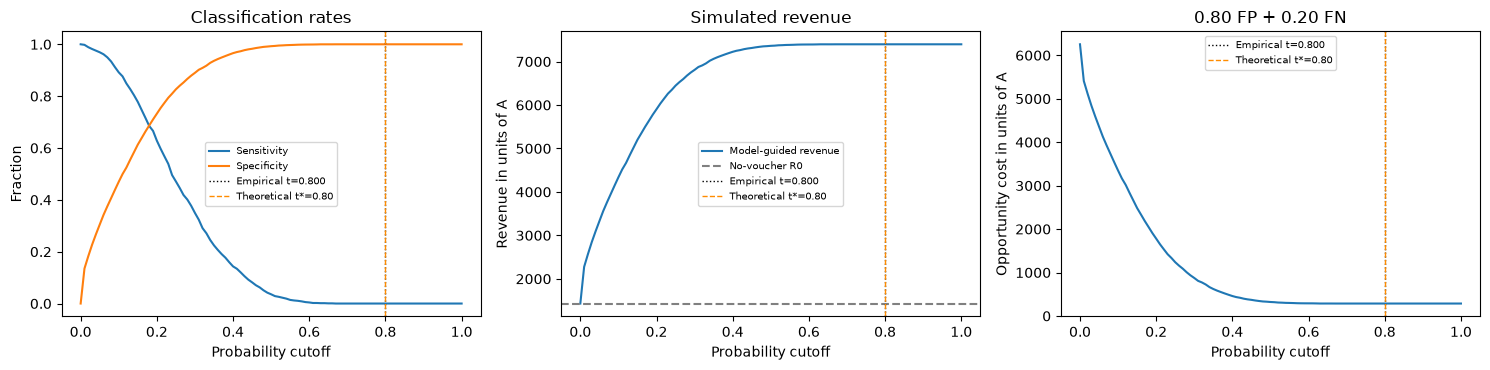

,threshold,TN,FP,FN,TP,sensitivity,specificity,R0_A,Rmodel_A,delta_A,relative_lift,voucher_count,weighted_opportunity_cost_A
setting,,,,,,,,,,,,,
default,0.5,7759,57,1380,51,0.0356,0.9927,1431.0,7362.2,5931.2,4.1448,9139,321.6
theoretical,0.8,7816,0,1431,0,0.0000,1.0000,1431.0,7397.6,5966.6,4.1695,9247,286.2
empirical optimum,0.8,7816,0,1431,0,0.0000,1.0000,1431.0,7397.6,5966.6,4.1695,9247,286.2


In [17]:
threshold_grid=np.unique(np.r_[np.linspace(0,1,101),THEORY_THRESHOLD,T_OPT])
threshold_rows=[{'threshold':float(t),**revenue_at(ytr,P_TRAIN,float(t)),
    'weighted_opportunity_cost_A':.80*confusion_rates(ytr,P_TRAIN,float(t))['FP']+
                                    .20*confusion_rates(ytr,P_TRAIN,float(t))['FN']}
    for t in threshold_grid]
THRESHOLD_CURVE=pd.DataFrame(threshold_rows)
fig,axes=plt.subplots(1,3,figsize=(15,3.8))
axes[0].plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.sensitivity,label='Sensitivity')
axes[0].plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.specificity,label='Specificity')
axes[0].set(xlabel='Probability cutoff',ylabel='Fraction',title='Classification rates')
axes[1].plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.Rmodel_A,label='Model-guided revenue')
axes[1].axhline(THRESHOLD_CURVE.iloc[0].R0_A,color='grey',ls='--',label='No-voucher R0')
axes[1].set(xlabel='Probability cutoff',ylabel='Revenue in units of A',title='Simulated revenue')
axes[2].plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.weighted_opportunity_cost_A)
axes[2].set(xlabel='Probability cutoff',ylabel='Opportunity cost in units of A',title='0.80 FP + 0.20 FN')
for ax in axes:
    ax.axvline(T_OPT,color='black',ls=':',lw=1,label=f'Empirical t={T_OPT:.3f}')
    ax.axvline(THEORY_THRESHOLD,color='darkorange',ls='--',lw=1,label=f'Theoretical t*={THEORY_THRESHOLD:.2f}')
    ax.legend(fontsize=7,loc='best')
plt.tight_layout(); plt.show()
threshold_comparison=[]
for label,t in [('default',.5),('theoretical',THEORY_THRESHOLD),('empirical optimum',T_OPT)]:
    threshold_comparison.append({'setting':label,'threshold':t,**revenue_at(ytr,P_TRAIN,t)})
THRESHOLD_COMPARE=pd.DataFrame(threshold_comparison).set_index('setting')
display(THRESHOLD_COMPARE.round(4))

In [18]:
TRAIN_THRESHOLD_RESULT=revenue_at(ytr,P_TRAIN,T_OPT)
THEORY_THRESHOLD_RESULT=revenue_at(ytr,P_TRAIN,THEORY_THRESHOLD)
voucher_fraction=TRAIN_THRESHOLD_RESULT['voucher_count']/len(ytr)
theory_voucher_fraction=THEORY_THRESHOLD_RESULT['voucher_count']/len(ytr)
high_score_count=int(np.sum(P_TRAIN>=THEORY_THRESHOLD))
display(Markdown(f"""
**Computed threshold interpretation.** The OOF revenue-optimal cutoff is {T_OPT:.4f}, {T_OPT-THEORY_THRESHOLD:+.4f} from the theoretical 0.80 reference. At that cutoff, the model-guided rule issues vouchers to {TRAIN_THRESHOLD_RESULT['voucher_count']:,} of {len(ytr):,} training sessions ({voucher_fraction:.2%}). At the 0.80 reference, it issues vouchers to {THEORY_THRESHOLD_RESULT['voucher_count']:,} sessions ({theory_voucher_fraction:.2%}); {high_score_count:,} scores are at or above 0.80. The 0.80 decision boundary follows if each score represents the true purchase probability without a voucher. The empirical cutoff is selected for revenue on these same OOF outcomes, not for a separate model-quality property. Under A1, a high voucher share follows from assuming guaranteed conversion.
"""))


**Computed threshold interpretation.** The OOF revenue-optimal cutoff is 0.8000, +0.0000 from the theoretical 0.80 reference. At that cutoff, the model-guided rule issues vouchers to 9,247 of 9,247 training sessions (100.00%). At the 0.80 reference, it issues vouchers to 9,247 sessions (100.00%); 0 scores are at or above 0.80. The 0.80 decision boundary follows if each score represents the true purchase probability without a voucher. The empirical cutoff is selected for revenue on these same OOF outcomes, not for a separate model-quality property. Under A1, a high voucher share follows from assuming guaranteed conversion.


The threshold extension separates ranking from policy: changing the cutoff moves sensitivity and specificity along the selected model's ROC curve, while AUC stays fixed. The revenue plot follows the two stated scenarios and the unchanged baseline. Finite-sample threshold optimization can produce an empirical cutoff that differs from the theoretical 0.80 reference; the threshold is not chosen using test labels.

## 9. Extension: training CV versus historical test

**Objective.** Evaluate the classifier chosen by mean training-CV ROC-AUC using its fold-mean and pooled OOF AUC and historical test AUC, then apply the threshold optimized on its training OOF predictions to the historical test set. **Method:** fit the selected pipeline once on the full training partition, obtain test probabilities, and compute confusion outcomes. No model or threshold is retuned on test data.

In [19]:
FINAL_PIPE=clone(CONFIGS[WINNER]).fit(Xtr,ytr)
P_TEST=FINAL_PIPE.predict_proba(Xte)[:,1]
TRAIN_R=revenue_at(ytr,P_TRAIN,T_OPT); TEST_R=revenue_at(yte,P_TEST,T_OPT)
TEST_AUC=roc_auc_score(yte,P_TEST); TEST_AP=average_precision_score(yte,P_TEST)
AUDIT=pd.DataFrame([
 {'evaluation':'Training OOF, pooled','AUC':roc_auc_score(ytr,P_TRAIN),'AP':average_precision_score(ytr,P_TRAIN),**TRAIN_R},
 {'evaluation':'Historical test, fixed threshold','AUC':TEST_AUC,'AP':TEST_AP,**TEST_R}
]).set_index('evaluation')
display(AUDIT.round(4))
print(f'Mean fold CV AUC: {CV_AUC:.4f} ± {TOP.fold_auc_sd:.4f}; pooled OOF AUC: {roc_auc_score(ytr,P_TRAIN):.4f}; mean fold CV AP: {TOP.mean_fold_ap:.4f} ± {TOP.fold_ap_sd:.4f}; pooled OOF AP: {average_precision_score(ytr,P_TRAIN):.4f}; test AUC: {TEST_AUC:.4f}; test AP: {TEST_AP:.4f}')
print(f'Pooled OOF minus test AUC: {roc_auc_score(ytr,P_TRAIN)-TEST_AUC:+.4f}')
print('Test confusion matrix; rows=actual [0,1], columns=predicted Buy [0,1]:')
display(pd.DataFrame([[TEST_R['TN'],TEST_R['FP']],[TEST_R['FN'],TEST_R['TP']]],
    index=['Actual no purchase','Actual purchase'],columns=['Predicted no','Predicted Buy']))
cv_test_auc_gap=CV_AUC-TEST_AUC
if TEST_R['voucher_count']==len(yte):
    test_policy_note=(f"At this fixed cutoff the rule issues vouchers to every one of the {len(yte):,} historical test sessions (sensitivity {TEST_R['sensitivity']:.3f}, specificity {TEST_R['specificity']:.3f}); it makes no selective distinction on this partition. The simulated revenue result therefore follows from A1's guaranteed conversion assumption and is not evidence of classifier-driven real sales growth.")
else:
    test_policy_note=(f"The fixed rule issues vouchers to {TEST_R['voucher_count']:,} of {len(yte):,} historical test sessions ({TEST_R['voucher_count']/len(yte):.2%}); these figures remain conditional on A1 and do not establish classifier-driven real sales growth.")
display(Markdown(f"""
**Computed CV-to-test interpretation.** Mean fold AUC was {CV_AUC:.4f}, pooled OOF AUC was {roc_auc_score(ytr,P_TRAIN):.4f}, and historical test AUC was {TEST_AUC:.4f} and test AP was {TEST_AP:.4f} (mean-fold minus test gap {cv_test_auc_gap:+.4f}). Sensitivity changed from {TRAIN_R['sensitivity']:.3f} in OOF training predictions to {TEST_R['sensitivity']:.3f} on test; specificity changed from {TRAIN_R['specificity']:.3f} to {TEST_R['specificity']:.3f}. These differences describe sample variation and possible selection optimism; the test partition was previously viewed, so it is not fresh independent confirmation.

{test_policy_note}
"""))


,AUC,AP,TN,FP,FN,TP,sensitivity,specificity,R0_A,Rmodel_A,delta_A,relative_lift,voucher_count,weighted_opportunity_cost_A
evaluation,,,,,,,,,,,,,,
"Training OOF, pooled",0.7609,0.3351,7816,0,1431,0,0.0,1.0,1431.0,7397.6,5966.6,4.1695,9247,286.2
"Historical test, fixed threshold",0.7423,0.3290,2606,0,477,0,0.0,1.0,477.0,2466.4,1989.4,4.1706,3083,95.4


Mean fold CV AUC: 0.7612 ± 0.0220; pooled OOF AUC: 0.7609; mean fold CV AP: 0.3407 ± 0.0349; pooled OOF AP: 0.3351; test AUC: 0.7423; test AP: 0.3290
Pooled OOF minus test AUC: +0.0186
Test confusion matrix; rows=actual [0,1], columns=predicted Buy [0,1]:


,Predicted no,Predicted Buy
Actual no purchase,2606,0
Actual purchase,477,0



**Computed CV-to-test interpretation.** Mean fold AUC was 0.7612, pooled OOF AUC was 0.7609, and historical test AUC was 0.7423 and test AP was 0.3290 (mean-fold minus test gap +0.0189). Sensitivity changed from 0.000 in OOF training predictions to 0.000 on test; specificity changed from 1.000 to 1.000. These differences describe sample variation and possible selection optimism; the test partition was previously viewed, so it is not fresh independent confirmation.

At this fixed cutoff the rule issues vouchers to every one of the 3,083 historical test sessions (sensitivity 0.000, specificity 1.000); it makes no selective distinction on this partition. The simulated revenue result therefore follows from A1's guaranteed conversion assumption and is not evidence of classifier-driven real sales growth.


### Test result interpretation and limitations

The dynamic interpretation below reports all four confusion outcomes and both revenue scenarios. Positive simulated revenue change means the model-guided policy exceeds the no-voucher baseline under A1–A4; it does not establish an actual voucher effect. Voucher counts include both actual buyers receiving an unnecessary discount (FN) and assumed conversions among non-buyers (TN).

**Limitations.** Voucher response is unobserved and guaranteed conversion is unverified. The dataset has no voucher predictor or intervention outcome; vouchers are hypothetical actions after classification. Results simulate sales revenue, not profitability; product costs, margins and operating costs are absent. Session predictors such as browsing duration, exit/bounce measures and `PageValues` may only be known at or after session completion; `PageValues` is excluded, but other predictor timing must be checked before real-time deployment. The data cover sessions from one historical retailer and year; results may not transfer to other retailers or periods. The observational unit is a session, and unique customer identities are unavailable, so repeated sessions cannot be grouped. The historical test partition was previously examined and is not fresh independent confirmation. Finally, selecting the model and threshold on the same OOF predictions makes OOF strategy revenue optimistic; a later independent evaluation would be needed for an unbiased estimate.

In [20]:
def business_sentence(name,r):
    verdict='higher' if r['delta_A']>1e-12 else ('lower' if r['delta_A'] < -1e-12 else 'equal')
    return (f"{name}: **R0={r['R0_A']:.1f}A**, **Rmodel={r['Rmodel_A']:.1f}A**, "
            f"**change={r['delta_A']:+.1f}A ({r['relative_lift']:+.2%})**; simulated revenue is {verdict} than baseline. "
            f"TP={r['TP']}, FP={r['FP']}, FN={r['FN']}, TN={r['TN']}; vouchers issued={r['voucher_count']:,}.")
display(Markdown(f"""
**Training OOF, selected threshold {T_OPT:.4f}.** {business_sentence('No-voucher versus model-guided',TRAIN_R)}

**Historical test, same fixed threshold.** {business_sentence('No-voucher versus model-guided',TEST_R)}

- **TP:** predicted Buy, actually Buy; no voucher and full-price purchase.
- **FP:** predicted Buy, actually No Buy; no voucher and a potential discounted conversion is missed.
- **FN:** predicted No Buy, actually Buy; voucher is issued although the session would have purchased without it.
- **TN:** predicted No Buy, actually No Buy; voucher is issued and converts under A1.

The no-voucher baseline is observed purchases (`TP+FN`) and is fixed for threshold comparisons. Simulated revenue uses `TP + 0.80(FN+TN)` in units of A. The labels remain unchanged. These results quantify the assumptions, not a forecast or causal effect.
"""))


**Training OOF, selected threshold 0.8000.** No-voucher versus model-guided: **R0=1431.0A**, **Rmodel=7397.6A**, **change=+5966.6A (+416.95%)**; simulated revenue is higher than baseline. TP=0, FP=0, FN=1431, TN=7816; vouchers issued=9,247.

**Historical test, same fixed threshold.** No-voucher versus model-guided: **R0=477.0A**, **Rmodel=2466.4A**, **change=+1989.4A (+417.06%)**; simulated revenue is higher than baseline. TP=0, FP=0, FN=477, TN=2606; vouchers issued=3,083.

- **TP:** predicted Buy, actually Buy; no voucher and full-price purchase.
- **FP:** predicted Buy, actually No Buy; no voucher and a potential discounted conversion is missed.
- **FN:** predicted No Buy, actually Buy; voucher is issued although the session would have purchased without it.
- **TN:** predicted No Buy, actually No Buy; voucher is issued and converts under A1.

The no-voucher baseline is observed purchases (`TP+FN`) and is fixed for threshold comparisons. Simulated revenue uses `TP + 0.80(FN+TN)` in units of A. The labels remain unchanged. These results quantify the assumptions, not a forecast or causal effect.


## 10. Conclusion and machine-readable project summary

**Interpretation.** The final dynamic display consolidates the ROC-AUC-selected model, its revenue-optimized threshold, discrimination, confusion outcomes and the two required revenue scenarios. Cross-validation and test AUC describe discrimination; simulated revenue describes the thresholded policy under the stated assumptions. They answer different questions.

In [21]:
def json_number(value):
    if value is None or not np.isfinite(value): return None
    return float(value) if isinstance(value,(float,np.floating)) else int(value)
def summary_metrics(r):
    return {k:json_number(r[k]) for k in ['TP','FP','FN','TN','sensitivity','specificity',
        'voucher_count','R0_A','Rmodel_A','delta_A','relative_lift',
        'weighted_opportunity_cost_A']}
SUMMARY={
 'selected_candidate':WINNER,
 'model_selection_criterion':'highest mean five-fold training ROC-AUC; exact ties by candidate label',
 'threshold_selection':'OOF simulated-revenue optimum for frozen AUC-selected model only',
 'threshold':json_number(T_OPT),
 'mean_cv_auc':json_number(CV_AUC),
 'cv_auc_fold_sd':json_number(TOP.fold_auc_sd),
 'mean_cv_average_precision':json_number(TOP.mean_fold_ap),
 'cv_average_precision_fold_sd':json_number(TOP.fold_ap_sd),
 'pooled_oof_auc':json_number(roc_auc_score(ytr,P_TRAIN)),
 'pooled_oof_average_precision':json_number(average_precision_score(ytr,P_TRAIN)),
 'test_auc':json_number(TEST_AUC),
 'test_average_precision':json_number(TEST_AP),
 'training_oof':summary_metrics(TRAIN_R),
 'historical_test':summary_metrics(TEST_R),
 'candidate_designs':int(len(LEDGER)),
 'successful_candidates':int(LED.status.eq('OK').sum()),
 'failed_candidates':int(LED.status.eq('FAILED').sum()),
 'cost_ratio_FN_to_FP':'1:4',
 'assumptions':['A1 guaranteed conversion','A2 20% discount','A3 common order value A','A4 observed labels are no-voucher behaviour']}
print('PROJECT SUMMARY — JSON\n' + json.dumps(SUMMARY,indent=2,allow_nan=False))

PROJECT SUMMARY — JSON
{
  "selected_candidate": "Logistic | zeroind",
  "model_selection_criterion": "highest mean five-fold training ROC-AUC; exact ties by candidate label",
  "threshold_selection": "OOF simulated-revenue optimum for frozen AUC-selected model only",
  "threshold": 0.8,
  "mean_cv_auc": 0.7611606287043668,
  "cv_auc_fold_sd": 0.022013011335942273,
  "mean_cv_average_precision": 0.34069180967252277,
  "cv_average_precision_fold_sd": 0.03490063894150928,
  "pooled_oof_auc": 0.7608866615596883,
  "pooled_oof_average_precision": 0.3350886248974599,
  "test_auc": 0.742292822079671,
  "test_average_precision": 0.3289560697045131,
  "training_oof": {
    "TP": 0,
    "FP": 0,
    "FN": 1431,
    "TN": 7816,
    "sensitivity": 0.0,
    "specificity": 1.0,
    "voucher_count": 9247,
    "R0_A": 1431.0,
    "Rmodel_A": 7397.6,
    "delta_A": 5966.6,
    "relative_lift": 4.169531795946891,
    "weighted_opportunity_cost_A": 286.2
  },
  "historical_test": {
    "TP": 0,
    "FP"